In [1]:
from multiclass_functions import *
import torch
from torch import nn, optim
from torchvision import datasets, transforms
from torch.utils.data import TensorDataset, DataLoader
import numpy as np
import matplotlib.pyplot as plt
import os
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
print(DEVICE)

cpu


In [ ]:
BATCH_SIZE = 32
LR = 1e-3
EPOCH = 5
criterion = nn.CrossEntropyLoss()
new_model_train = True
model_type = 'MLP_drop'
dataset = 'MNIST'

os.makedirs("results", exist_ok=True)

save_model_path = f'results/{model_type}_{dataset}.pt'


In [ ]:
transform = transforms.ToTensor()
train_DS = datasets.MNIST(root = 'data', train=True, download=False, transform=transform)
test_DS = datasets.MNIST(root = 'data', train=False, download=False, transform=transform)
train_DL = DataLoader(train_DS, batch_size = BATCH_SIZE, shuffle=True)
test_DL = DataLoader(test_DS, batch_size = BATCH_SIZE, shuffle=False)

In [18]:
class MLP(nn.Module):
  def __init__(self):
    super().__init__()
    self.linear = nn.Sequential(nn.Linear(28*28, 30),
                                nn.BatchNorm1d(30),
                                nn.ReLU(),
                                nn.Linear(30, 10))

  def forward(self, x):
    x = torch.flatten(x, start_dim=1)
    x = self.linear(x)
    return x

class MLP_drop(nn.Module):
  def __init__(self):
    super().__init__()
    self.linear = nn.Sequential(nn.Linear(28*28, 30),
                                nn.BatchNorm1d(30),
                                nn.ReLU(),
                                nn.Dropout(p=0.3),
                                nn.Linear(30, 10))

  def forward(self, x):
    x = torch.flatten(x, start_dim=1)
    x = self.linear(x)
    return x

In [19]:
model = globals()[model_type]().to(DEVICE)

Epoch : 1, train loss : 0.585
------------------------------
Epoch : 2, train loss : 0.398
------------------------------
Epoch : 3, train loss : 0.360
------------------------------
Epoch : 4, train loss : 0.340
------------------------------
Epoch : 5, train loss : 0.323
------------------------------


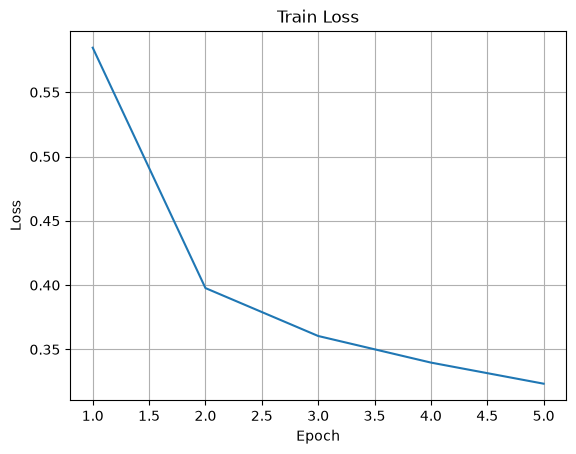

In [20]:
if new_model_train :
  optimizer = optim.Adam(model.parameters(), lr=LR)
  loss_history = Train(model, train_DL, criterion, optimizer, EPOCH)

  torch.save(model, save_model_path)

  plt.plot(range(1, EPOCH+1), loss_history)
  plt.xlabel('Epoch')
  plt.ylabel('Loss')
  plt.title('Train Loss')
  plt.grid()

In [21]:
load_model = torch.load(save_model_path,
                        map_location=DEVICE, weights_only=False)

In [22]:
Test(load_model, test_DL)
print(count_params(load_model))

Test accuracy : 9540/ 10000 (95.4 %)
23920


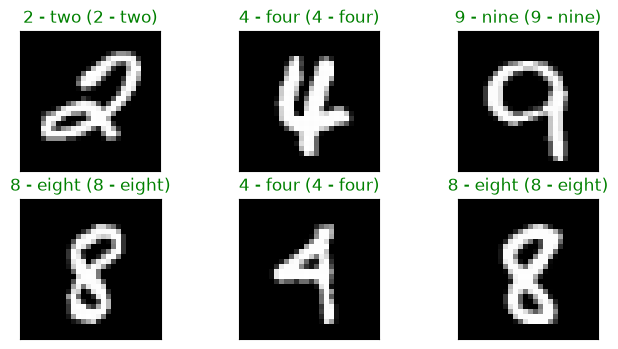

In [23]:
Test_plot(load_model, test_DL)

(array([0, 1, 2, 3, 4, 5, 6, 7, 8, 9]),
 [Text(0, 0, '0 - zero'),
  Text(1, 0, '1 - one'),
  Text(2, 0, '2 - two'),
  Text(3, 0, '3 - three'),
  Text(4, 0, '4 - four'),
  Text(5, 0, '5 - five'),
  Text(6, 0, '6 - six'),
  Text(7, 0, '7 - seven'),
  Text(8, 0, '8 - eight'),
  Text(9, 0, '9 - nine')])

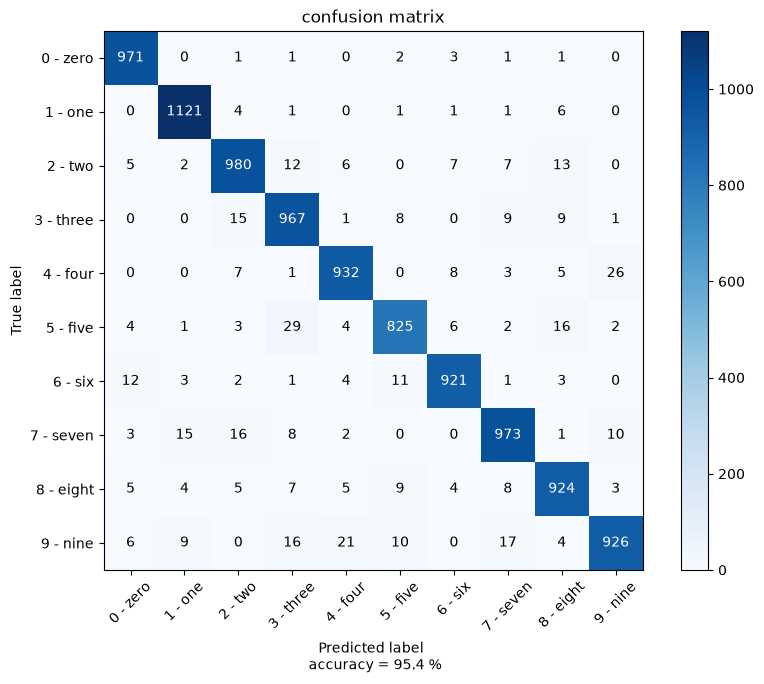

In [24]:
confusion = get_conf(load_model, test_DL)
plot_confusion_matrix(confusion, test_DS.classes)
plt.xticks(rotation=45)

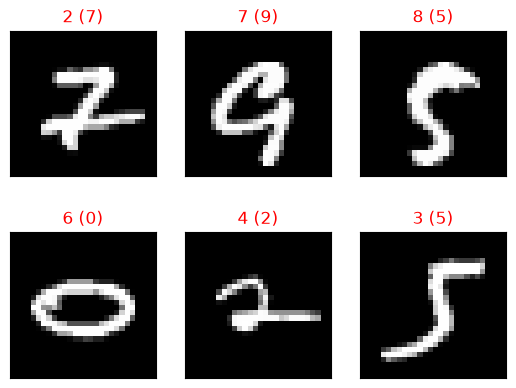

In [25]:
# 틀린것만 모아보기
cnt = 0
load_model.eval()

with torch.no_grad():
  for x_batch, y_batch in test_DL :
    x_batch = x_batch.to(DEVICE)
    y_batch = y_batch.to(DEVICE)
    y_hat = load_model(x_batch)
    pred = y_hat.argmax(dim=1)

    false_idx = pred != y_batch
    X_false = x_batch[false_idx,...].to('cpu')
    pred_false = pred[false_idx,...].to('cpu')
    Y_false = y_batch[false_idx,...].to('cpu')

    if X_false.shape[0] != 0:
      if cnt == 6:
        break
      for i in range(X_false.shape[0]):
        cnt += 1
        pred_class = pred_false[i].item()
        true_class = Y_false[i].item()
        plt.subplot(2,3, cnt, xticks=[], yticks=[])
        plt.imshow(X_false[i,0,...], cmap='gray')
        plt.title(f'{pred_class} ({true_class})', color='r')
        if cnt == 6:
          break